In [1]:
# %pip install xgboost
# %pip install lightgbm
# %pip install catboost
# %pip install optuna

import pandas as pd
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_score
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

from sklearn.ensemble import HistGradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
import optuna
from optuna.samplers import TPESampler

from pathlib import Path
import sys
sys.path.insert(0, str(Path.cwd().parent))
from src.classification_lib import N_TRIALS

In [2]:
# df = pd.read_parquet('./../data/exports/features_nutriscore_20261020.parquet')
df = pd.read_parquet('./../data/sample/nutriscope_ml_sample.parquet')

In [3]:
# classification_lib > preparation()

features_num = [
    'nova_group', 'additives_n',
    'energy-kcal_100g', 'fat_100g', 'saturated-fat_100g', 'carbohydrates_100g',
    'sugars_100g', 'proteins_100g', 'salt_100g'
]
features_num_opt = ['fiber_100g', 'fruits-vegetables-legumes_100g']
features_cat = ['pnns_groups_1', 'pnns_groups_2']
features_derived = ['sugar_to_carbs_ratio', 'sat_to_total_fat_ratio', 'energy_kcal_error']
target = 'nutriscore_grade'
features = features_num + features_num_opt + features_cat

def derived_features(X):
    X = X.copy()

    # Ratio : Part des sucres par rapport aux glucides totaux
    X["sugar_to_carbs_ratio"] = X["sugars_100g"] / (
        X["carbohydrates_100g"] + 1e-5
    )

    # Ratio : Part des graisses saturées par rapport aux lipides totaux
    X["sat_to_total_fat_ratio"] = X["saturated-fat_100g"] / (
        X["fat_100g"] + 1e-5
    )

    # Écart d'énergie (Formule d'Atwater pour les kcal)
    fibers = X["fiber_100g"].fillna(0)
    energy_calculated_kcal = (
        (4 * X["proteins_100g"])
        + (4 * X["carbohydrates_100g"])
        + (9 * X["fat_100g"])
        + (2 * fibers)
    )
    X["energy_kcal_error"] = energy_calculated_kcal - X["energy-kcal_100g"]

    return X

preprocessor = ColumnTransformer([
    ('numeric', Pipeline([
        ('feature_engineering', FunctionTransformer(derived_features, validate=False)),
        ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
        ('scaler', StandardScaler()),
    ]), features_num + features_num_opt),
    ('categorial', OneHotEncoder(handle_unknown='ignore', min_frequency=0.01), features_cat),
])

X_train = df[df['split'] == 'train'][features]
y_train = df[df['split'] == 'train'][target]
X_test = df[df['split'] == 'test'][features]
y_test = df[df['split'] == 'test'][target]

In [4]:
models = {
    'Régression logistique multinomiale': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
}

results = {}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = ['f1_macro', 'accuracy', 'balanced_accuracy']

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model),
    ])

    res = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring)

    results[name] = {
        "F1 Macro": f"{res['test_f1_macro'].mean():.4f} (+/- {res['test_f1_macro'].std():.4f})",
        "Accuracy": f"{res['test_accuracy'].mean():.4f} (+/- {res['test_accuracy'].std():.4f})",
        "Accuracy Équilibrée": f"{res['test_balanced_accuracy'].mean():.4f} (+/- {res['test_balanced_accuracy'].std():.4f})",
        "Temps Ajustement (s)": f"{res['fit_time'].mean():.3f}s",
        "Temps Prédiction (s)": f"{res['score_time'].mean():.3f}s",
    }

df_results = pd.DataFrame.from_dict(results, orient="index")
display(df_results.round(4))

,F1 Macro,Accuracy,Accuracy Équilibrée,Temps Ajustement (s),Temps Prédiction (s)
Régression logistique multinomiale,0.7640 (+/- 0.0065),0.8026 (+/- 0.0041),0.7627 (+/- 0.0062),4.055s,0.064s
Random Forest,0.8580 (+/- 0.0056),0.8773 (+/- 0.0043),0.8536 (+/- 0.0052),1.944s,0.095s


In [5]:
# ValueError: Invalid classes inferred from unique values of `y`.  Expected: [0 1 2 3 4], got ['a' 'b' 'c' 'd' 'e']
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test) # Optionnel pour la suite, mais indispensable pour le test final

models = {
    'HistGradientBoosting': HistGradientBoostingClassifier(random_state=42),
    'XGBoost': XGBClassifier(random_state=42),
    'LightGBM': LGBMClassifier(random_state=42, verbosity=-1),
    'CatBoost': CatBoostClassifier(random_state=42, verbose=0, allow_writing_files=False)
}

results = {}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = ['f1_macro', 'accuracy', 'balanced_accuracy']

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model),
    ])

    res = cross_validate(pipeline, X_train, y_train_encoded, cv=cv, scoring=scoring)

    results[name] = {
        "F1 Macro": f"{res['test_f1_macro'].mean():.4f} (+/- {res['test_f1_macro'].std():.4f})",
        "Accuracy": f"{res['test_accuracy'].mean():.4f} (+/- {res['test_accuracy'].std():.4f})",
        "Accuracy Équilibrée": f"{res['test_balanced_accuracy'].mean():.4f} (+/- {res['test_balanced_accuracy'].std():.4f})",
        "Temps Ajustement (s)": f"{res['fit_time'].mean():.3f}",
        "Temps Prédiction (s)": f"{res['score_time'].mean():.3f}",
    }

df_results = pd.DataFrame.from_dict(results, orient="index")
display(df_results.round(4))

,F1 Macro,Accuracy,Accuracy Équilibrée,Temps Ajustement (s),Temps Prédiction (s)
HistGradientBoosting,0.8909 (+/- 0.0050),0.9087 (+/- 0.0044),0.8892 (+/- 0.0048),1.981,0.039
XGBoost,0.8933 (+/- 0.0046),0.9099 (+/- 0.0034),0.8920 (+/- 0.0048),2.902,0.043
LightGBM,0.8911 (+/- 0.0047),0.9082 (+/- 0.0038),0.8899 (+/- 0.0047),2.863,0.036
CatBoost,0.8877 (+/- 0.0043),0.9058 (+/- 0.0032),0.8859 (+/- 0.0042),8.597,0.030


In [6]:
print('Budget XGBClassifier:')
temps_par_pli = float(results['XGBoost']['Temps Ajustement (s)']) + float(results['XGBoost']['Temps Prédiction (s)'])
temps_total = N_TRIALS * 5 * float(temps_par_pli) * 6 # x6 par rapport au temps réel
minutes = int(temps_total // 60)
secondes = int(temps_total % 60)
print(f"5 plis x {N_TRIALS} essais x (Temps Ajustement: {results['XGBoost']['Temps Ajustement (s)']} + Temps Prédiction: {results['XGBoost']['Temps Prédiction (s)']}) = {minutes} min {secondes} s")

Budget XGBClassifier:
5 plis x 30 essais x (Temps Ajustement: 2.902 + Temps Prédiction: 0.043) = 44 min 10 s


In [7]:
# XGBClassifier

optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = {
        "n_estimators" : trial.suggest_int("n_estimators", 50, 800),
        "max_depth" : trial.suggest_int("max_depth", 2, 10),
        "learning_rate" : trial.suggest_float("learning_rate", 0.01, 0.5),
        'subsample' : trial.suggest_float('subsample', 0.0, 1.0)
    }

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", XGBClassifier(random_state=42, **params)),
    ])

    scores = cross_val_score(
        pipeline, X_train, y_train_encoded, cv=5, scoring="f1_macro"
    )
    return scores.mean()

study = optuna.create_study(
    direction="maximize",
    sampler=TPESampler(seed=42),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=5),
)
study.optimize(objective, n_trials=N_TRIALS)

print(f"Meilleur score : {study.best_value}")
print("Meilleurs hyperparamètres :")
for nom, valeur in study.best_params.items():
    print(f"{nom}: {valeur}")

Meilleur score : 0.8848755011948246
Meilleurs hyperparamètres :
n_estimators: 335
max_depth: 10
learning_rate: 0.10347460157138903
subsample: 0.9990595926527632


In [8]:
print('Budget LGBMClassifier:')
temps_par_pli = float(results['LightGBM']['Temps Ajustement (s)']) + float(results['LightGBM']['Temps Prédiction (s)'])
temps_total = N_TRIALS * 5 * float(temps_par_pli) * 4 # x4 par rapport au temps réel
minutes = int(temps_total // 60)
secondes = int(temps_total % 60)
print(f"5 plis x {N_TRIALS} essais x (Temps Ajustement: {results['LightGBM']['Temps Ajustement (s)']} + Temps Prédiction: {results['LightGBM']['Temps Prédiction (s)']}) = {minutes} min {secondes} s")

Budget LGBMClassifier:
5 plis x 30 essais x (Temps Ajustement: 2.863 + Temps Prédiction: 0.036) = 28 min 59 s


In [9]:
# LGBMClassifier

optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = {
        "n_estimators" : trial.suggest_int("n_estimators", 50, 800),
        "max_depth" : trial.suggest_int("max_depth", 2, 10),
        "learning_rate" : trial.suggest_float("learning_rate", 0.01, 0.5),
        'subsample' : trial.suggest_float('subsample', 0.0, 1.0)
    }

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", LGBMClassifier(random_state=42, **params)),
    ])

    scores = cross_val_score(
        pipeline, X_train, y_train_encoded, cv=5, scoring="f1_macro"
    )
    return scores.mean()

study = optuna.create_study(
    direction="maximize",
    sampler=TPESampler(seed=42),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=5),
)
study.optimize(objective, n_trials=N_TRIALS)

print(f"Meilleur score : {study.best_value}")
print("Meilleurs hyperparamètres :")
for nom, valeur in study.best_params.items():
    print(f"{nom}: {valeur}")

Meilleur score : 0.8854780956321351
Meilleurs hyperparamètres :
n_estimators: 497
max_depth: 9
learning_rate: 0.07595365404738545
subsample: 0.07157306912699152


In [10]:
models = {
    'Régression logistique multinomiale': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'HistGradientBoosting': HistGradientBoostingClassifier(random_state=42),
    'LightGBM Tuned': LGBMClassifier(
        random_state=42,
        verbosity=-1,
        n_estimators=497,
        max_depth=9,
        learning_rate=0.07595365404738545,
        subsample=0.07157306912699157
    ),
    'CatBoost': CatBoostClassifier(random_state=42, verbose=0, allow_writing_files=False),
    'XGBoost Tuned': XGBClassifier(
        random_state=42,
        n_estimators=530,
        max_depth=6,
        learning_rate=0.16228195608113927,
        subsample=0.9221608233975894
    )
}

results = {}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = ['f1_macro', 'accuracy', 'balanced_accuracy']

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model),
    ])

    res = cross_validate(pipeline, X_train, y_train_encoded, cv=cv, scoring=scoring)

    results[name] = {
        "F1 Macro": f"{res['test_f1_macro'].mean():.4f} (+/- {res['test_f1_macro'].std():.4f})",
        "Accuracy": f"{res['test_accuracy'].mean():.4f} (+/- {res['test_accuracy'].std():.4f})",
        "Accuracy Équilibrée": f"{res['test_balanced_accuracy'].mean():.4f} (+/- {res['test_balanced_accuracy'].std():.4f})",
        "Temps Ajustement (s)": f"{res['fit_time'].mean():.3f}",
        "Temps Prédiction (s)": f"{res['score_time'].mean():.3f}",
    }

df_results = pd.DataFrame.from_dict(results, orient="index")
display(df_results.round(4))

,F1 Macro,Accuracy,Accuracy Équilibrée,Temps Ajustement (s),Temps Prédiction (s)
Régression logistique multinomiale,0.7640 (+/- 0.0065),0.8026 (+/- 0.0041),0.7627 (+/- 0.0062),3.680,0.027
Random Forest,0.8580 (+/- 0.0056),0.8773 (+/- 0.0043),0.8536 (+/- 0.0052),1.828,0.071
HistGradientBoosting,0.8909 (+/- 0.0050),0.9087 (+/- 0.0044),0.8892 (+/- 0.0048),1.915,0.040
LightGBM Tuned,0.8992 (+/- 0.0073),0.9151 (+/- 0.0057),0.8981 (+/- 0.0071),8.126,0.114
CatBoost,0.8877 (+/- 0.0043),0.9058 (+/- 0.0032),0.8859 (+/- 0.0042),3.817,0.019
XGBoost Tuned,0.8977 (+/- 0.0065),0.9141 (+/- 0.0049),0.8962 (+/- 0.0065),11.323,0.056


In [11]:
# Utiliser preparation()

features_num = [
    'nova_group', 'additives_n',
    'energy-kcal_100g', 'fat_100g', 'saturated-fat_100g', 'carbohydrates_100g',
    'sugars_100g', 'proteins_100g', 'salt_100g'
]
features_num_opt = ['fiber_100g', 'fruits-vegetables-legumes_100g']
features_cat = ['pnns_groups_1', 'pnns_groups_2']
features_derived = ['sugar_to_carbs_ratio', 'sat_to_total_fat_ratio', 'energy_kcal_error']
target = 'nutriscore_grade'
features = features_num + features_num_opt + features_cat

def derived_features(X):
    X = X.copy()

    # Ratio : Part des sucres par rapport aux glucides totaux
    X["sugar_to_carbs_ratio"] = X["sugars_100g"] / (
        X["carbohydrates_100g"] + 1e-5
    )

    # Ratio : Part des graisses saturées par rapport aux lipides totaux
    X["sat_to_total_fat_ratio"] = X["saturated-fat_100g"] / (
        X["fat_100g"] + 1e-5
    )

    # Écart d'énergie (Formule d'Atwater pour les kcal)
    fibers = X["fiber_100g"].fillna(0)
    energy_calculated_kcal = (
        (4 * X["proteins_100g"])
        + (4 * X["carbohydrates_100g"])
        + (9 * X["fat_100g"])
        + (2 * fibers)
    )
    X["energy_kcal_error"] = energy_calculated_kcal - X["energy-kcal_100g"]

    return X

preprocessor = ColumnTransformer([
    ('numeric', Pipeline([
        ('feature_engineering', FunctionTransformer(derived_features, validate=False)),
        ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
        ('scaler', StandardScaler()),
    ]), features_num + features_num_opt),
    ('categorial', OneHotEncoder(handle_unknown='ignore', min_frequency=0.01), features_cat),
])

X_train = df[df['split'] == 'train'][features]
y_train = df[df['split'] == 'train'][target]
X_test = df[df['split'] == 'test'][features]
y_test = df[df['split'] == 'test'][target]

In [12]:
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LGBMClassifier(
        random_state=42,
        verbosity=-1,
        n_estimators=497,
        max_depth=9,
        learning_rate=0.07595365404738545,
        subsample=0.07157306912699157
    )),
])

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

--- MATRICE DE CONFUSION NORMALISÉE ---


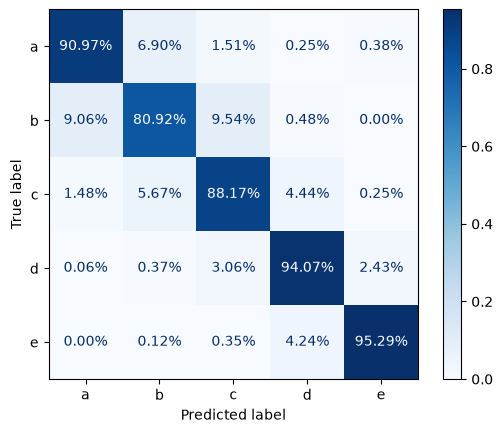

In [13]:
print("--- MATRICE DE CONFUSION NORMALISÉE ---")
cm = confusion_matrix(
    y_test, y_pred, labels=pipeline.classes_, normalize="true"
)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=pipeline.classes_
)
disp.plot(cmap="Blues", values_format=".2%")

In [14]:
print("--- TOP 5 DES COUPLES D'ERREURS LES PLUS FRÉQUENTS ---")
proba = pipeline.predict_proba(X_test)
confiance = proba.max(axis=1)
ordre_classe = {'a': 0, 'b': 1, 'c': 2, 'd': 3, 'e': 4}
idx_test = df[df['split'] == 'test'].index
erreurs = df.loc[idx_test, ['code', 'product_name'] + features].copy() #
erreurs['nutriscore_reel'] = y_test.values
erreurs['nutriscore_predit'] = y_pred # prédictions sur le test
erreurs['confiance'] = confiance
erreurs['ecart_classe'] = (
    erreurs['nutriscore_reel'].map(ordre_classe) - erreurs['nutriscore_predit'].map(ordre_classe)
).abs()
erreurs = erreurs[erreurs['nutriscore_reel'] != erreurs['nutriscore_predit']]
erreurs_triees = erreurs.sort_values(['ecart_classe', 'confiance'], ascending=[False, False])
colonnes_affichage = ['code', 'product_name', 'nutriscore_reel', 'nutriscore_predit', 'ecart_classe', 'confiance']
display(erreurs_triees[colonnes_affichage].head(5))

--- TOP 5 DES COUPLES D'ERREURS LES PLUS FRÉQUENTS ---


,code,product_name,nutriscore_reel,nutriscore_predit,ecart_classe,confiance
14692,3435079013717,Craquant rose framboise noir,a,e,4,1.000000
5516,30182189,Préparation penne toscane épinards tomates,a,e,4,0.999987
12151,3292590853020,2 boudins blancs au foie de canard,a,e,4,0.999843
6265,3073190010880,Papillons Kilo Malin,d,a,3,0.988748
20192,3760109640312,Les Oublies de Nancy (chocolat ),a,d,3,0.961397


In [15]:
print("--- GRAVITÉ DES ERREURS ---")
ordre_classe = {"a": 0, "b": 1, "c": 2, "d": 3, "e": 4}
y_test_num = np.array([ordre_classe[val] for val in y_test])
y_pred_num = np.array([ordre_classe[val] for val in y_pred])

error_distances = np.abs(y_test_num - y_pred_num)
dists, counts = np.unique(error_distances, return_counts=True)
gravity = dict(zip(dists, counts))
for dist in sorted(gravity.keys()):
    count = gravity[dist]
    if dist == 0:
        print(f"Corrects : {count} produits")
    elif dist == 1:
        print(f"Écart de 1 cran : {count} produits")
    elif dist == 2:
        print(f"Écart de 2 crans : {count} produits")
    else:
        print(f"Écart de {dist} crans : {count} produits")

--- GRAVITÉ DES ERREURS ---
Corrects : 5453 produits
Écart de 1 cran : 456 produits
Écart de 2 crans : 48 produits
Écart de 3 crans : 5 produits
Écart de 4 crans : 3 produits


In [16]:
print("--- PERFORMANCE PAR RAYON (Triée par F1-Score Macro du pire au meilleur) ---")

# La fonction reçoit chaque sous-DataFrame associé à un rayon
def get_rayon_performance(rayon):
    # Calcule des métriques
    report = classification_report(
        rayon["true_grade"],
        rayon["pred_grade"],
        output_dict=True,
        zero_division=0
    )
    # Extraction du F1-Score Macro
    return report["macro avg"]["f1-score"]

df_test = df[df["split"] == "test"].copy()
df_test["true_grade"] = y_test
df_test["pred_grade"] = y_pred

rayon_perf = (
    df_test.groupby("pnns_groups_1")
    .apply(get_rayon_performance)
    .reset_index(name="f1_score_macro")
)

# Tri du pire au meilleur
rayon_perf = rayon_perf.sort_values(by="f1_score_macro")

print(rayon_perf.to_string(index=False))


--- PERFORMANCE PAR RAYON (Triée par F1-Score Macro du pire au meilleur) ---
          pnns_groups_1  f1_score_macro
    Alcoholic beverages        0.388889
          Sugary snacks        0.807187
   Cereals and potatoes        0.838154
  Fruits and vegetables        0.845574
              Beverages        0.850483
        Composite foods        0.862411
Milk and dairy products        0.896600
         Fat and sauces        0.900141
           Salty snacks        0.907375
         Fish Meat Eggs        0.914615


In [17]:
print("--- FOCUS SUR 5 PRODUITS HÉSITANTS (Proches de la frontière, écart de probabilité faible (< 0.15)) ---")

# On cherche des lignes où les deux plus fortes probabilités sont sur [b, c] ou [d, e]
# Index des classes : a=0, b=1, c=2, d=3, e=4
hesitant_indices = []

for idx, probs in enumerate(proba):
    sorted_classes = np.argsort(probs)[::-1]  # Classes triées de la plus probable à la moins probable
    top1, top2 = sorted_classes[0], sorted_classes[1]

    # Vérification de l'hésitation entre b (1) et c (2) OU d (3) et e (4)
    if (set([top1, top2]) == {1, 2}) or (set([top1, top2]) == {3, 4}):
        # Écart de probabilité faible (< 0.15) signifiant une vraie hésitation
        if abs(probs[top1] - probs[top2]) < 0.15:
            hesitant_indices.append(idx)

# Extraction des produits correspondants dans le DataFrame de test d'origine
df_hesitant = df_test.iloc[hesitant_indices].head(5)

# Colonnes d'affichage
display_cols = [
    "product_name",
    "code",
    "true_grade",
    "pred_grade",
    "energy-kcal_100g",
    "sugars_100g",
    "salt_100g",
]
# On garde uniquement les colonnes disponibles pour éviter les KeyError
available_cols = [c for c in display_cols if c in df_test.columns]

if not df_hesitant.empty:
    print(df_hesitant[available_cols].to_string(index=False))
else:
    print("Aucun produit ne correspond strictement aux critères d'hésitation définis.")

--- FOCUS SUR 5 PRODUITS HÉSITANTS (Proches de la frontière, écart de probabilité faible (< 0.15)) ---
                     product_name          code true_grade pred_grade  energy-kcal_100g  sugars_100g  salt_100g
    Frosted mini wheats, original 0038000318290          c          c            352.00        20.37      0.005
         CHICKEN & SWEETCORN SOUP      01016154          b          b             49.92         1.70      0.500
Hauts de cuisse de poulet paprika 0215111053337          c          c            203.00         0.00      0.700
               Original BBQ Sauce 0810020931822          e          d            190.00        43.00      1.000
     Pains aux raisins feuilletés 2000002851400          e          e            333.00        20.00      0.650


### Sauvegarde du modèle : 

In [18]:
import joblib

model_filename = "./../models/LightGBM_nutriscope.pkl"
joblib.dump(pipeline, model_filename)

['./../models/LightGBM_nutriscope.pkl']

### Test prediction :

In [19]:
model = joblib.load(model_filename)

# Création d'un nouveau produit (Données brutes uniquement)
new_product = pd.DataFrame(
    {
        # --- Variables numériques obligatoires ---
        "nova_group": [4.0],
        "additives_n": [2.0],
        "energy-kcal_100g": [350.0],
        "fat_100g": [12.0],
        "saturated-fat_100g": [4.5],
        "carbohydrates_100g": [50.0],
        "sugars_100g": [22.0],
        "proteins_100g": [6.5],
        "salt_100g": [0.8],
        # --- Variables numériques optionnelles ---
        "fiber_100g": [3.2],
        "fruits-vegetables-legumes_100g": [15.0],
        # --- Variables catégorielles ---
        "pnns_groups_1": ["Sugary snacks"],
        "pnns_groups_2": ["Biscuits and cakes"],
    }
)

prediction = pipeline.predict(new_product)

# Affichage du Nutri-Score prédit
print(f"Nutri-Score estimé pour ce produit : {prediction[0]}")

Nutri-Score estimé pour ce produit : d
